# Project 2 Assignment

## Assignment Overview & Instructions

The objective of Project 2 is to extract time series features for human activity
monitoring.

### Dataset
The following [link](https://www.uni-mannheim.de/dws/research/projects/activity-recognition/#dataset_realworld) provides human activity data for 15 subjects. Click on each subject to
access the time series data.   
For this project consider accelerometer data for all the 15
subjects for walking, running, climbing up and climbing down for chest sensor only.

### Task 1: Load the data

You might find downloading the dataset from [here](https://drive.google.com/drive/folders/1JneWV9NL1v2R8LpiTNKw2oqTgd3o2Sgx) more convenient.

In [109]:
# YOUR CODE HERE
import pandas as pd

activitie = ['walking', 'running', 'climbingup', 'climbingdown']
data = {}

for subject in range(1, 16):      # Loop for subject (Because we want 15 subjects)
    for activity in activitie:    # Loop for activities 
        path = f'project2_data_chest/s{subject}_acc_{activity}_{activity}_chest.csv'   # s1_acc_climbingdown_climbingdown_chest
        data[(subject, activity)] = pd.read_csv(path)    # read csv file and store it in the key -> data[(subject, activity)]

len(data)

60

In [110]:
data[(1, 'walking')].head()       # show first 5 rows of subject = 1 and do walking activity

,id,attr_time,attr_x,attr_y,attr_z
0,1,1435993159405,-2.160767,9.400234,0.565032
1,2,1435993159425,-2.176928,9.395446,0.621295
2,3,1435993159443,-2.151190,9.382876,0.588974
3,4,1435993159463,-2.135029,9.319430,0.545878
4,5,1435993159483,-2.168548,9.306262,0.586579


### Task 2: Feature Extraction
Compute permutation entropy and complexity across all parameter combinations:
- Dimensions: 3, 4, 5, 6
- Delays: 1, 2, 3
- Signal lengths: 1024, 2048, 4096
- All three axes (x, y, z)

**Sample output table**

|   |   |   |   |   |   |   |   |
|---|---|---|---|---|---|---|---|
| Subject  | Accelerometer axis   | Signal length  | Dimension  | Delay  | Permutation entropy  | Complexity  | Activity  |
| 1 to 15  | x or y or z  | 1024 or 2048 or 4096  | 3 or 4 or 5 or 6  | 1 or 2 or 3  |   |   | Walking or running or climbing up or climbing down  |

This table/dataframe is expected to have 6480 rows.

### Formula of permutation entropy and complexity
- Permutation entropy = -[sum of p(pi) x log p(pi)]
  
  Normalized Permutation Entropy = -[sum of p(pi) x log p(pi)] / log(number of ordinal pattern found)
  
  PE norm = 0 -> Completely ordered
  
  PE norm = 1 -> Completely random
  
- Complexity = Q0 x J[P,Pe] x Hs

  Q0 = Normalizing constant

  J[P,Pe] = Jensen-Shannon divergrnce between: P -> Actual probability distribution, Pe -> Uniform distribution (maximum entropy)

  
  Hs = Permutation entropy

In [111]:
import math

In [112]:
# YOUR CODE HERE (from module 8)
''' This module has essential functions supporting
fast and effective computation of permutation entropy and
its different variations.'''
import numpy as np


def s_entropy(freq_list):     # compute of the frequency distribution
    ''' This function computes the shannon entropy of a given frequency distribution.
    USAGE: shannon_entropy(freq_list)
    ARGS: freq_list = Numeric vector representing the frequency distribution
    OUTPUT: A numeric value representing shannon's entropy'''
    freq_list = [element for element in freq_list if element != 0]     # filter only freq_list that is not equal to 0 because log(0) is impossible.
    sh_entropy = 0.0                           
    for freq in freq_list:                     # Loop for the frequency 
        sh_entropy += freq * np.log(freq)      # formula of shanon entropy
    sh_entropy = -sh_entropy                   # Return to positive. (Change the sign)
    return(sh_entropy)

def ordinal_patterns(ts, embdim, embdelay):    # compute the ordinal pattern of a time series
    ''' This function computes the ordinal patterns of a time series for a given embedding dimension and embedding delay.
    USAGE: ordinal_patterns(ts, embdim, embdelay)
    ARGS: ts = Numeric vector representing the time series, embdim = embedding dimension (3<=embdim<=7 prefered range), embdelay =  embdding delay
    OUPTUT: A numeric vector representing frequencies of ordinal patterns'''
    m, t = embdim, embdelay     # m = dimension D, t = delay
    x = ts if isinstance(ts, np.ndarray) else np.array(ts)       # check if ts is numpy array or not if not change it to numpy array

    tmp = np.zeros((x.shape[0], m))           # create empty table (number of information, dimension)
    for i in range(m):                        # loop for dimension
        tmp[:, i] = np.roll(x, i*t)           # shift the x to i*t and keep it on column i of tmp table
    partition = tmp[(t*(m-1)):, :]            # remove the row that over shift
    permutation = np.argsort(partition)       # rank order from low to high
    idx = _hash(permutation)                  # Convert sorting pattern to code (Index)

    counts = np.zeros(math.factorial(m))      # remove np. from counts = np.zeros(math.factorial(m)) from out because it show the error
    for i in range(counts.shape[0]):          # loop of the possible pattern
        counts[i] = (idx == i).sum()          # count the number of occur i
    return list(counts[counts != 0].astype(int))     # return into list of frequency that is greater than 0 and convert to integer

def _hash(x):         # Change from pattern to code
    m, n = x.shape    # get the shape from m to row and n to col
    if n == 1:
        return np.zeros(m)  # if col = 1 return to 0
    return np.sum(np.apply_along_axis(lambda y: y < x[:, 0], 0, x), axis=1) * math.factorial(n-1) + _hash(x[:, 1:])      # remove np. from math.factorial(n-1) out because it show the error 


def p_entropy(op):
    ordinal_pat = op
    max_entropy = np.log(len(ordinal_pat))                           #Find the maximum entropy value.
    p = np.divide(np.array(ordinal_pat), float(sum(ordinal_pat)))    # Change the number of frequency to probability by divided by sum of ordinal pattern
    return(s_entropy(p)/max_entropy)

def complexity(op):
    ''' This function computes the complexity of a time series defined as: Comp_JS = Q_o * JSdivergence * pe
    Q_o = Normalizing constant
    JSdivergence = Jensen-Shannon divergence
    pe = permutation entopry
    ARGS: ordinal pattern'''
    pe = p_entropy(op)        # calculate PE of the pattern first
    # calculate the constant and normalize constant (Q0)
    constant1 = (0.5+((1 - 0.5)/len(op)))* np.log(0.5+((1 - 0.5)/len(op)))
    constant2 = ((1 - 0.5)/len(op))*np.log((1 - 0.5)/len(op))*(len(op) - 1)
    constant3 = 0.5*np.log(len(op))
    Q_o = -1/(constant1+constant2+constant3)

    temp_op_prob = np.divide(op, sum(op))                   # convert the frequency to probability of information
    temp_op_prob2 = (0.5*temp_op_prob)+(0.5*(1/len(op)))    # create the mix distribution b/w data and uniform distribution
    JSdivergence = (s_entropy(temp_op_prob2) - 0.5 * s_entropy(temp_op_prob) - 0.5 * np.log(len(op)))      # Calculate the distance (Divergence) between data and random distribution (Uniform Distribution)
    Comp_JS = Q_o * JSdivergence * pe          # calculate complexity
    return(Comp_JS)

# we did not used in Task 2
def weighted_ordinal_patterns(ts, embdim, embdelay):
    m, t = embdim, embdelay
    x = ts if isinstance(ts, np.ndarray) else np.array(ts)

    tmp = np.zeros((x.shape[0], m))
    for i in range(m):
        tmp[:, i] = np.roll(x, i*t)
    partition = tmp[(t*(m-1)):, :]
    xm = np.mean(partition, axis=1)
    weight = np.mean((partition - xm[:, None])**2, axis=1)
    permutation = np.argsort(partition)
    idx = _hash(permutation)
    counts = np.zeros(np.math.factorial(m))
    for i in range(counts.shape[0]):
        counts[i] = sum(weight[i == idx])

    return list(counts[counts != 0])

In [113]:
# Generating a time series with sine values
import math
time_series = []
for i in range(365):                   # Loop 365 (365 day simulation)
    value = math.sin(math.radians(i))  # Example with sine function
    time_series.append(value)          # Add value to list

In [114]:
# Compute ordinal patterns with embedding dimension = 3 and embedding delay = 1
op_timeseries = ordinal_patterns(time_series, 3, 1)

In [115]:
# Compute permutation entropy
pe_timeseries = p_entropy(op_timeseries)
print(pe_timeseries)

0.5246103226528828


In [116]:
# Compute complexity
complexity_timeseries = complexity(op_timeseries)
print(complexity_timeseries)

0.27816502922902525


In [117]:
activitie = ['walking', 'running', 'climbingup', 'climbingdown']
dimensions = [3, 4, 5, 6]
delays = [1, 2, 3]
lengths = [1024, 2048, 4096]
axes = [('x', 'attr_x'), ('y', 'attr_y'), ('z', 'attr_z')]

rows = []
for subject in range(1, 16):             # Loop for subject (Because we want 15 subjects)
    for activity in activitie:           # Loop for activities
        for axis_label, column in axes:  # Loop for axis
            for length in lengths:       # Loop for signal length
                # takes the data of subject, activity, and also select the axis (uses only first length) to keep on signal
                signal = data[(subject, activity)][column].iloc[:length]   # .iloc[:length] -> cut signal data to the same length
                for dimension in dimensions:    # Loop for dimension
                    for delay in delays:        # Loop for delay
                        op = ordinal_patterns(signal, dimension, delay)    # convert to the ordinal pattern
                        pe = p_entropy(op)                                 # calculate PE
                        comp = complexity(op)                              # calculate complexity
                        rows.append({
                                'Subject': subject,
                                'Accelerometer axis': axis_label,
                                'Signal length': length,
                                'Dimension': dimension,
                                'Delay': delay,
                                'Permutation entropy': pe,
                                'Complexity': comp,
                                'Activity': activity
                            })

In [118]:
result = pd.DataFrame(rows)      # create the dataframe
len(result)

6480

In [119]:
result.head()    # show the first 5 row of the dataframe 

,Subject,Accelerometer axis,Signal length,Dimension,Delay,Permutation entropy,Complexity,Activity
0,1,x,1024,3,1,0.855987,0.119191,walking
1,1,x,1024,3,2,0.960795,0.036081,walking
2,1,x,1024,3,3,0.982091,0.017024,walking
3,1,x,1024,4,1,0.794190,0.199622,walking
4,1,x,1024,4,2,0.926851,0.086092,walking


### Task 3: Focus Your Analysis

Now select one particular subject of your choice (e.g 3), a particular attribute of your choice (e.g x) and a particular Signal length (e.g 2048) and filter the data for these specifics. You are only requited to filter the required data here. In the tasks 4 and 5, you will focus your analysis on this partcular subject for the specified accelerometer axis and signal length.



In [120]:
# YOUR CODE HERE
# filter subject = 1 on axis = x and signal length = 2048
filter = result[
        (result['Subject'] == 1) & (result['Accelerometer axis'] == 'x') & (result['Signal length'] == 2048)
]

len(filter)

48

In [121]:
filter.head()

,Subject,Accelerometer axis,Signal length,Dimension,Delay,Permutation entropy,Complexity,Activity
12,1,x,2048,3,1,0.844650,0.127396,walking
13,1,x,2048,3,2,0.960623,0.036399,walking
14,1,x,2048,3,3,0.984438,0.014920,walking
15,1,x,2048,4,1,0.779283,0.213100,walking
16,1,x,2048,4,2,0.931000,0.082783,walking


### Task 4: Waling vs Running

Use scatter plots to identify the optimal dimension and delay that best separate walking from running. Since you focused on a single dimension, a single subject and a single dimension, you will get 12 walking, running pairs for 4 dimensions and 3 delays, this should give rise to 12 panels, each showing a scatterplot.

After you have made the scatter plots, identify the optimum dimension and delay that provide the best separation between walking and running. Reason why this is your choice.

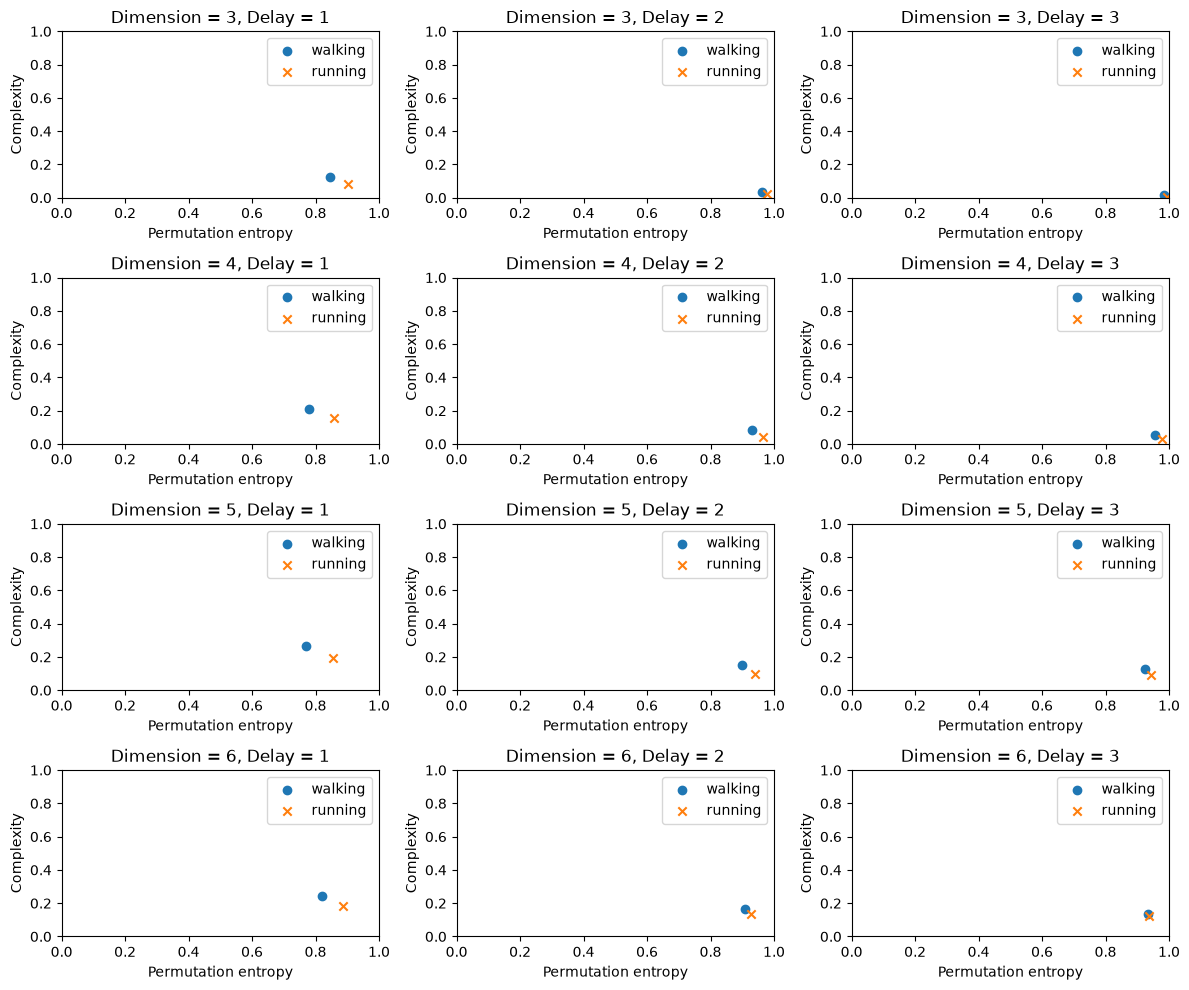

In [122]:
# YOUR CODE HERE
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 3, figsize=(12, 10))       # Make 12 plots: 4 rows (dimension) 3 columns (delay)
for i, dimension in enumerate(dimensions):             # Loop for row (dimension)
    for j, delay in enumerate(delays):                 # Loop for column (delay)
        ax = axes[i][j]                                # plot for row and column
        # walking row for dimension and delay
        walk = filter[
            (filter['Activity'] == 'walking') & (filter['Dimension'] == dimension) & (filter['Delay'] == delay)
        ]
        # running row for dimension and delay
        run = filter[
            (filter['Activity'] == 'running') & (filter['Dimension'] == dimension) & (filter['Delay'] == delay)
        ]
        x_walk = walk['Permutation entropy'].iloc[0]  # x values for walk
        y_walk = walk['Complexity'].iloc[0]           # y values for walk
        x_run = run['Permutation entropy'].iloc[0]    # x values for run
        y_run = run['Complexity'].iloc[0]             # y values for run
        ax.scatter(x_walk, y_walk, marker='o', label='walking')      # plot o (x and y axis for walk)
        ax.scatter(x_run, y_run, marker='x', label='running')        # plot x (x and y axis for run)
        ax.set_xlim(0, 1)      # plot on the same x scale (don't zoom)
        ax.set_ylim(0, 1)      # plot on the same y scale
        ax.set_title(f'Dimension = {dimension}, Delay = {delay}')    # set the title of each plot
        ax.set_xlabel('Permutation entropy')      # set name of x label
        ax.set_ylabel('Complexity')               # set name of y label
        ax.legend()    # show o is for walking and x is for running
plt.tight_layout()     # make it not overlap
plt.show()             # show the plot

In [123]:
filter[(filter['Dimension'] == 5) & (filter['Delay'] == 1)]    # filter all of activity that has d=5 and delay=1

,Subject,Accelerometer axis,Signal length,Dimension,Delay,Permutation entropy,Complexity,Activity
18,1,x,2048,5,1,0.769346,0.265207,walking
126,1,x,2048,5,1,0.855540,0.194731,running
234,1,x,2048,5,1,0.765386,0.247473,climbingup
342,1,x,2048,5,1,0.724470,0.277411,climbingdown


In [124]:
filter[(filter['Dimension'] == 4) & (filter['Delay'] == 1)]    # filter all of activity that has d=4 and delay=1

,Subject,Accelerometer axis,Signal length,Dimension,Delay,Permutation entropy,Complexity,Activity
15,1,x,2048,4,1,0.779283,0.213100,walking
123,1,x,2048,4,1,0.856955,0.155959,running
231,1,x,2048,4,1,0.797243,0.186721,climbingup
339,1,x,2048,4,1,0.743690,0.225202,climbingdown


> YOUR ANSWER HERE
- The optimum dimension and delay that provide the best separation between walking and running are Dimension = 5 and Delay = 1
- Dimension = 5, Delay = 1: PE walking = 0.769346, Complexity walking = 0.265207, PE running = 0.855540, Complexity running = 0.194731
- It clearly show that PE running is higher than PE walking and Complexity running is lower than Complexity walking
- Compare to Dimension = 4, Delay = 1 that has a lower distance than Dimension = 5, Delay = 1

### Task 5: Climbing Up vs. Climbing Down

Use scatter plots similar to task 4 to identify the optimal dimension and delay that best separate climbing up from climbing down.


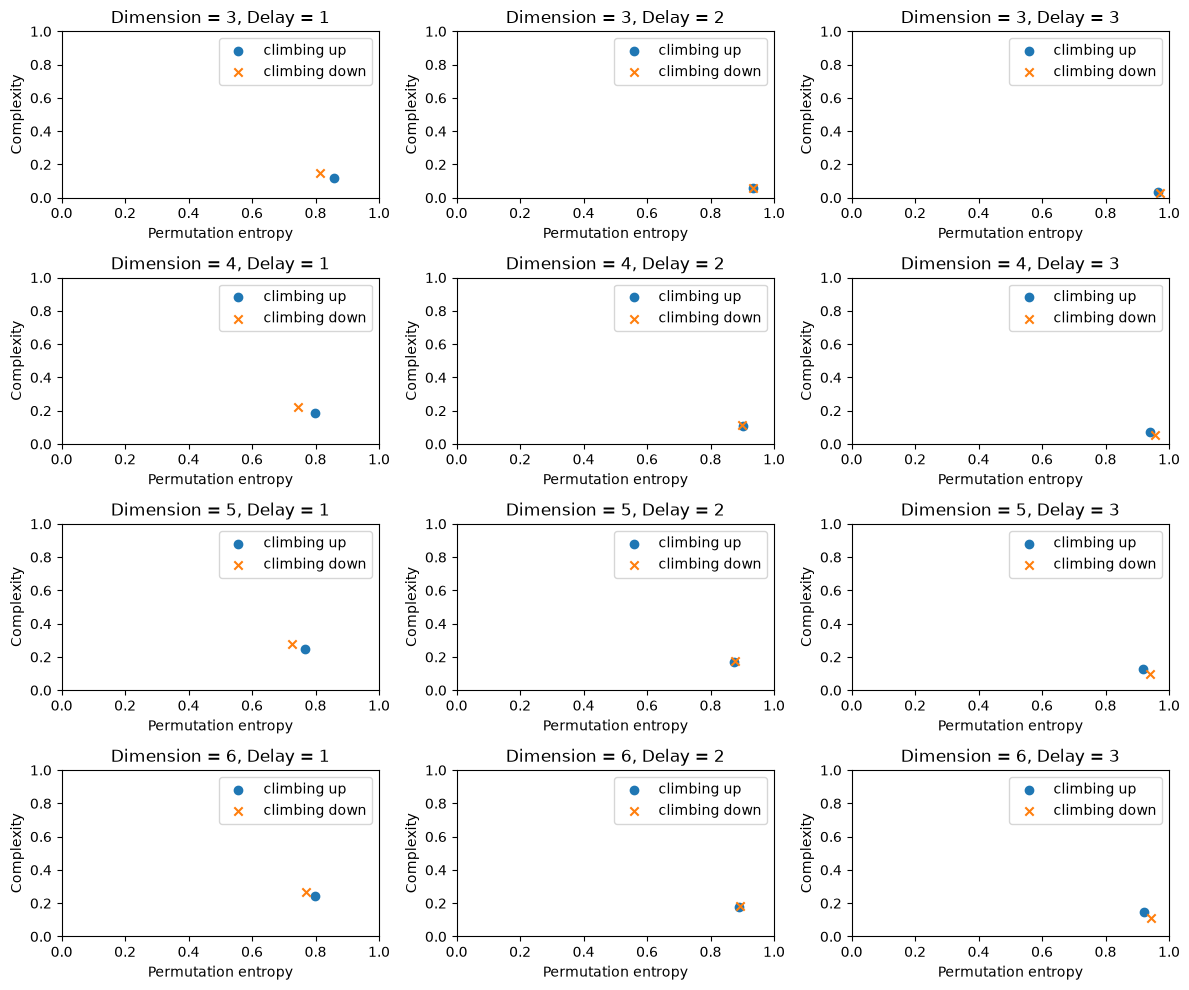

In [125]:
# YOUR CODE HERE
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 3, figsize=(12, 10))      # Make 12 plots: 4 rows (dimension) 3 columns (delay)
for i, dimension in enumerate(dimensions):            # Loop for row (dimension)
    for j, delay in enumerate(delays):                # Loop for column (delay)
        ax = axes[i][j]                               # plot for row and column
        # climbing up row for dimension and delay
        climbingup = filter[
            (filter['Activity'] == 'climbingup') & (filter['Dimension'] == dimension) & (filter['Delay'] == delay)
        ]
        # climbing down row for dimension and delay
        climbingdown = filter[
            (filter['Activity'] == 'climbingdown') & (filter['Dimension'] == dimension) & (filter['Delay'] == delay)
        ]
        x_cu = climbingup['Permutation entropy'].iloc[0]           # x values for climbing up
        y_cu = climbingup['Complexity'].iloc[0]                    # y values for climbing up
        x_cd = climbingdown['Permutation entropy'].iloc[0]         # x values for climbing down
        y_cd = climbingdown['Complexity'].iloc[0]                  # y values for climbing down
        ax.scatter(x_cu, y_cu, marker='o', label='climbing up')    # plot o (x and y axis for climbing up)
        ax.scatter(x_cd, y_cd, marker='x', label='climbing down')  # plot x (x and y axis for climbing down)
        ax.set_xlim(0, 1)      # plot on the same x scale (don't zoom)
        ax.set_ylim(0, 1)      # plot on the same y scale (don't zoom)
        ax.set_title(f'Dimension = {dimension}, Delay = {delay}')  # set the title of each plot
        ax.set_xlabel('Permutation entropy')      # set name of x label
        ax.set_ylabel('Complexity')               # set name of y label
        ax.legend()    # show o is for walking and x is for running
plt.tight_layout()     # make sure it not overlap
plt.show()             # show the plot

In [126]:
filter[(filter['Dimension'] == 4) & (filter['Delay'] == 1)]

,Subject,Accelerometer axis,Signal length,Dimension,Delay,Permutation entropy,Complexity,Activity
15,1,x,2048,4,1,0.779283,0.213100,walking
123,1,x,2048,4,1,0.856955,0.155959,running
231,1,x,2048,4,1,0.797243,0.186721,climbingup
339,1,x,2048,4,1,0.743690,0.225202,climbingdown


> YOUR ANSWER HERE
- the optimal dimension and delay that best separate climbing up from climbing down are Dimension = 4 and Delay = 1
- Dimension = 4, Delay = 1: PE climbing up = 0.797243, Complexity climbing up = 0.186721, PE climbing down = 0.743690, Complexity climbing down = 0.225202
- It clearly show that PE climbing up is higher than PE climbing down and Complexity climbing up is lower than Complexity climbing down

AI use disclosure: The AI that use is Muse 
- I used for explain the question that i understand is correct or not.
- I used to guide, brainstorm, and help debugg in the code errors and why it error.
- I used it to check my understang about the code that I have comment.

## Submitting your Project

Once you've completed your project, it's time to submit your work for grading.   
This week, you will submit your code file `Project 2.ipynb` for review.  

In order to submit your work, please follow the steps below:
1. Verify you've saved your work using the `Save` button within the Jupyter Notebook 
2. Download this notebook using the `File` -> `Download As` -> Choose the `Notebook (.ipynb)` format.
3. Access the following Step 2: Submit Project 2 item.
4. Complete all prompted fields, and upload your Jupyter Notebook file (Project 2.ipynb) in the indicated field.
5. Submit your notebook to "Step 2: Submit Project 2" by the deadline indicated within your course view for the Project 2 Assignment item.

## Grading Rubric

1. Task 1 = 5 points


2. Task 2 = 35 points


3. Task 3 = 10 points


4. Task 4 = 20 points


5. Task 5 = 20 points


6. 10 points for coding consistencies (follow PeP 8 style guide for coding)

    a. Proper commenting
    
    b. Proper variable names
    
    c. Inclusion of texts in notebook to explain all the steps
    
    d. Include formulas for permutation entropy and complexity in your notebook 

    e. Inclusion of all outputs of your code

Congratulations on completing the Project 2 Assignment!